<a href="https://colab.research.google.com/github/LTeamHackathon/L_Team_Hackaathon_Repository/blob/main/Dataset_B_Hackathon_Updated_Risk_Comparison_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hackathon Team Notebook

**Team:** LTeamHackathon  
**Date:** Wednesday 11 November

## How to use this notebook with 8-9 people
- Use **File > Save a copy in Drive** and work in your own copy.
- Only paste finished, working code into this shared notebook.
- Put your name in a comment at the top of every cell you add.
- Commit the final version to the GitHub repo.


## Team and roles

| Name | Role | GitHub username |
|------|------|-----------------|
|  | Team lead / presenter |  |
|  | Git person (merges work) |  |
|  | Data cleaning |  |
|  | Exploratory analysis |  |
|  | Modelling |  |
|  | Visualisation |  |
|  | Testing / evaluation |  |
|  | Slides / write-up |  |


## 1. Setup and reproducibility
This is an improved version of your original hackathon notebook. **Run the cells in order.** All figures are larger and labelled. Data loads directly from **Google Drive**; edit only the `DATA_DIR` line in the loading cell. Models use leakage-free pipelines. The hospitalisation risks are **hypothetical assumptions**, not observed medical outcomes.

**Academic integrity:** execute and commit the actual work during the allowed session; do not present illustrative medical parameters as sourced facts.

In [ ]:
# Run this cell first. Colab already includes most packages.
import os, time, warnings, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss,
                             accuracy_score, f1_score, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.base import clone
warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='talk', font_scale=0.90)
plt.rcParams.update({'figure.dpi':120,'savefig.dpi':180,'axes.titlesize':16,'axes.labelsize':13})
print('Libraries ready')

Libraries ready


## 2. Load the three datasets from Google Drive
**Before running:** upload the three CSVs into one folder in your Google Drive (e.g. `MyDrive/Hackathon_B/`). In the code below, change **only** `DATA_DIR` to your folder path. Run the cell and grant Drive access. If you work locally, the code uses `/mnt/data` as a fallback. No manual Colab-session uploads are required.

In [ ]:
# Option C: load from Google Drive (recommended)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    # CHANGE THIS to the exact folder path where you uploaded your CSV files
    DATA_DIR = '/content/drive/MyDrive/Hackathon_B/'

    # Fallback to root if the subfolder doesn't exist yet
    if not os.path.exists(DATA_DIR):
        DATA_DIR = '/content/drive/MyDrive/'
except ImportError:
    DATA_DIR = '/mnt/data'  # Local testing outside Colab

# Dynamic file detection to handle naming variations
def find_csv_path(base_dir, base_name):
    for name in [base_name, base_name.replace('.csv', '(1).csv'), base_name.replace('(1)', '')]:
        path = os.path.join(base_dir, name)
        if os.path.exists(path):
            return path
    # Fallback/Default path if not found
    return os.path.join(base_dir, base_name)

train_path = find_csv_path(DATA_DIR, 'dataset_B_training.csv')
test_path = find_csv_path(DATA_DIR, 'dataset_B_testing.csv')
example_path = find_csv_path(DATA_DIR, 'dataset_B_example_submission(1).csv')

print(f"Loading train from: {train_path}")
print(f"Loading test from: {test_path}")
print(f"Loading example from: {example_path}")

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)
example = pd.read_csv(example_path)

TARGET = 'h1n1_vaccine'
ID = 'respondent_id'
features = [c for c in train.columns if c not in [ID, TARGET]]
assert set(features) == set(test.columns) - {ID}, 'Train/test feature columns differ'
assert example[ID].equals(test[ID]), 'Example submission row order differs'
assert set(train[TARGET].dropna().unique()) == {0, 1}
print('Training:', train.shape, '| Testing:', test.shape, '| Example:', example.shape)
display(train.head(4))
display(test.head(4))

Mounted at /content/drive
Loading train from: /content/drive/MyDrive/dataset_B_training.csv
Loading test from: /content/drive/MyDrive/dataset_B_testing.csv
Loading example from: /content/drive/MyDrive/dataset_B_example_submission.csv
Training: (4756, 31) | Testing: (4749, 30) | Example: (4749, 2)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions
0,4757,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Female,"<= $75,000, Above Poverty",Not Married,Own,Not in Labor Force,"MSA, Principle City",0.0,0.0,NaN,0
1,4758,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,Female,NaN,NaN,NaN,NaN,"MSA, Not Principle City",0.0,0.0,NaN,0
2,4759,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Male,NaN,Married,Own,Not in Labor Force,"MSA, Principle City",1.0,0.0,NaN,0
3,4760,3.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,1.0,0.0,agriculture,1


## 3. Deep exploratory data analysis
The target is **vaccination acceptance** (`h1n1_vaccine`), not actual infection or hospital admission. The identifier is random and excluded from modelling. Look for missingness, class imbalance, group differences, and potential distribution shift. EDA below uses only labelled training data.

Training observations: 4756 | Features: 29
Duplicate respondent IDs: 0
Target distribution:


,Count
Vaccinated,
0,2882
1,1874


Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
h1n1_concern,4741.0,NaN,NaN,NaN,1.658933,0.892478,0.0,1.0,2.0,2.0,3.0
h1n1_knowledge,4734.0,NaN,NaN,NaN,1.30714,0.612811,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4739.0,NaN,NaN,NaN,0.057396,0.232622,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,NaN,NaN,NaN,0.74096,0.438154,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4752.0,NaN,NaN,NaN,0.077652,0.267651,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4748.0,NaN,NaN,NaN,0.842039,0.364743,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4747.0,NaN,NaN,NaN,0.359385,0.479871,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4741.0,NaN,NaN,NaN,0.341278,0.474189,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4736.0,NaN,NaN,NaN,0.704814,0.456174,0.0,0.0,1.0,1.0,1.0


,Training %,Testing %
employment_sector,49.7,50.6
health_insurance,40.5,41.7
income_poverty,15.0,16.8
doctor_recc_h1n1,6.7,7.3
rent_or_own,6.6,8.0
employment_status,4.9,5.8
marital_status,4.8,5.7
education,4.7,5.7
child_under_6_months,2.8,3.3
health_worker,2.8,3.1


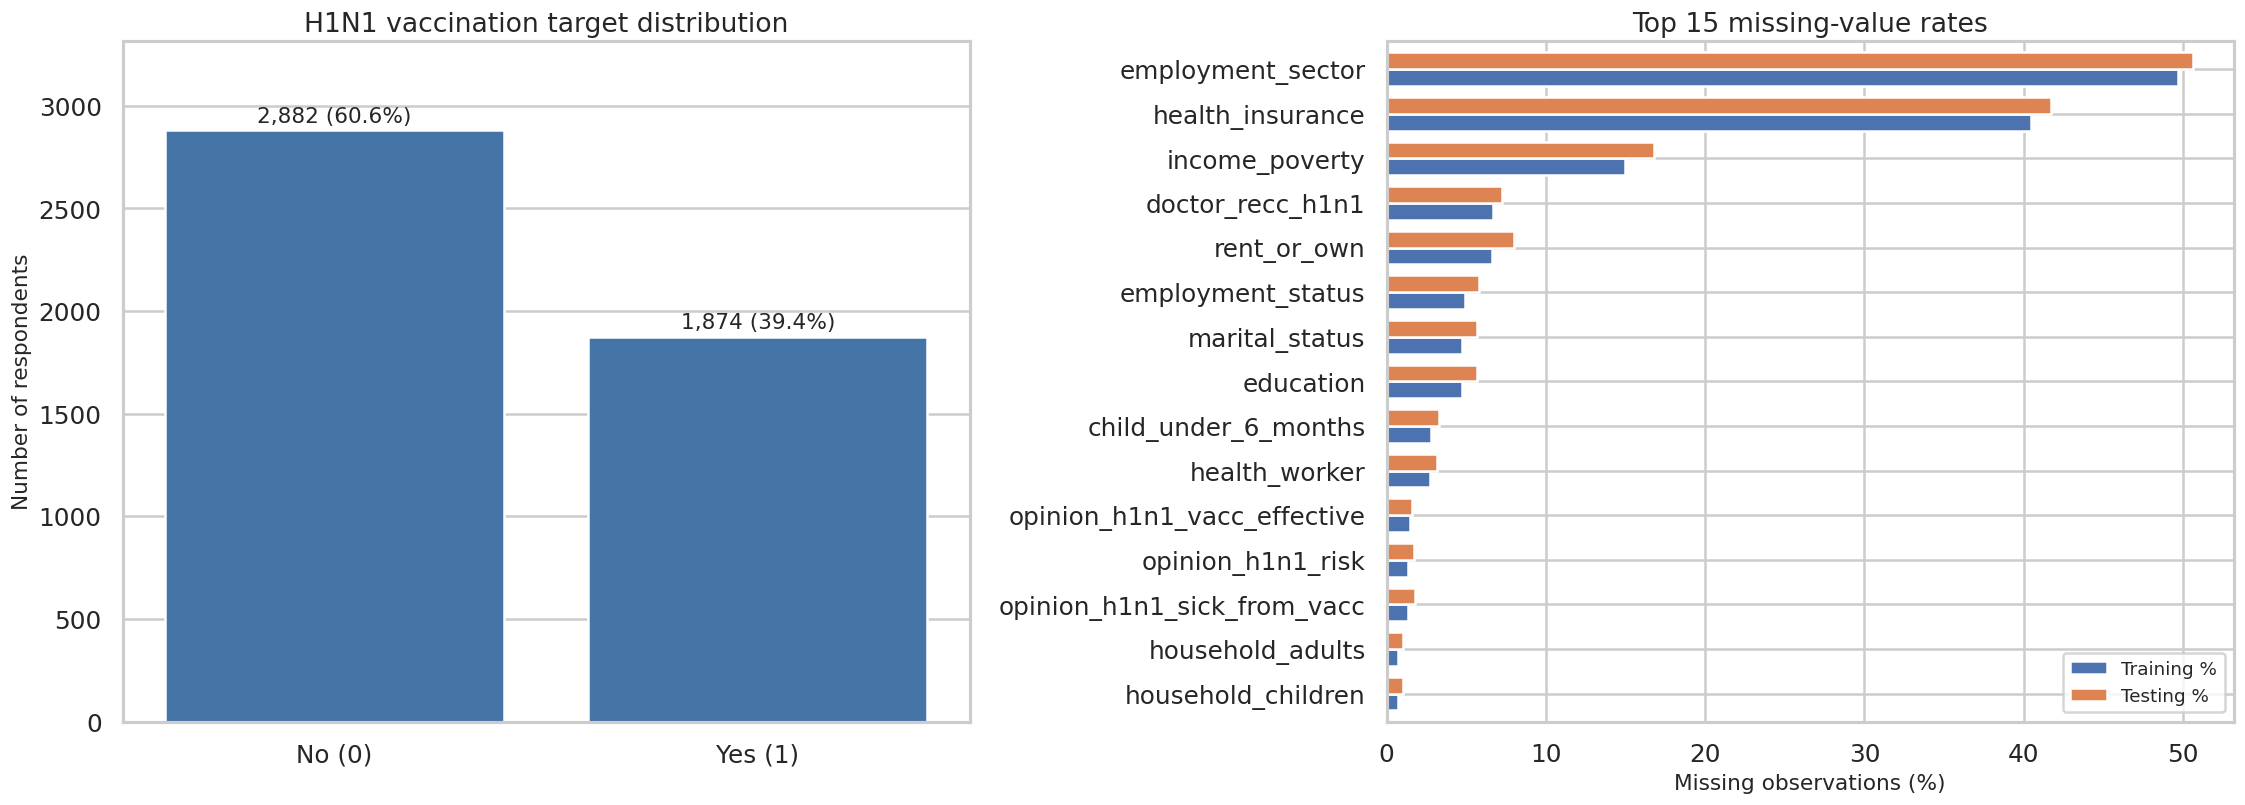

In [ ]:
# Basic EDA: dimensions, data quality and missing values
print('Training observations:', len(train), '| Features:', len(features))
print('Duplicate respondent IDs:', train[ID].duplicated().sum())
print('Target distribution:')
display(train[TARGET].value_counts().rename_axis('Vaccinated').to_frame('Count'))
print('Summary:')
display(train.describe(include='all').T)
missing = pd.DataFrame({'Training %': train[features].isna().mean()*100,
                        'Testing %': test[features].isna().mean()*100}).sort_values('Training %',ascending=False)
display(missing.round(1).head(20))

fig, axes = plt.subplots(1,2,figsize=(19,7))
counts = train[TARGET].value_counts().sort_index()
sns.barplot(x=['No (0)','Yes (1)'],y=counts.values,ax=axes[0],color='#3575b7')
for i,v in enumerate(counts.values):
    axes[0].text(i,v+40,f'{v:,} ({100*v/len(train):.1f}%)',ha='center',fontsize=13)
axes[0].set_ylim(0,max(counts)*1.15)
axes[0].set_title('H1N1 vaccination target distribution');axes[0].set_ylabel('Number of respondents')
plot_missing=missing.head(15).iloc[::-1]
plot_missing.plot(kind='barh',ax=axes[1],width=.75)
axes[1].set_title('Top 15 missing-value rates');axes[1].set_xlabel('Missing observations (%)')
axes[1].legend(fontsize=11)
plt.tight_layout();plt.show()

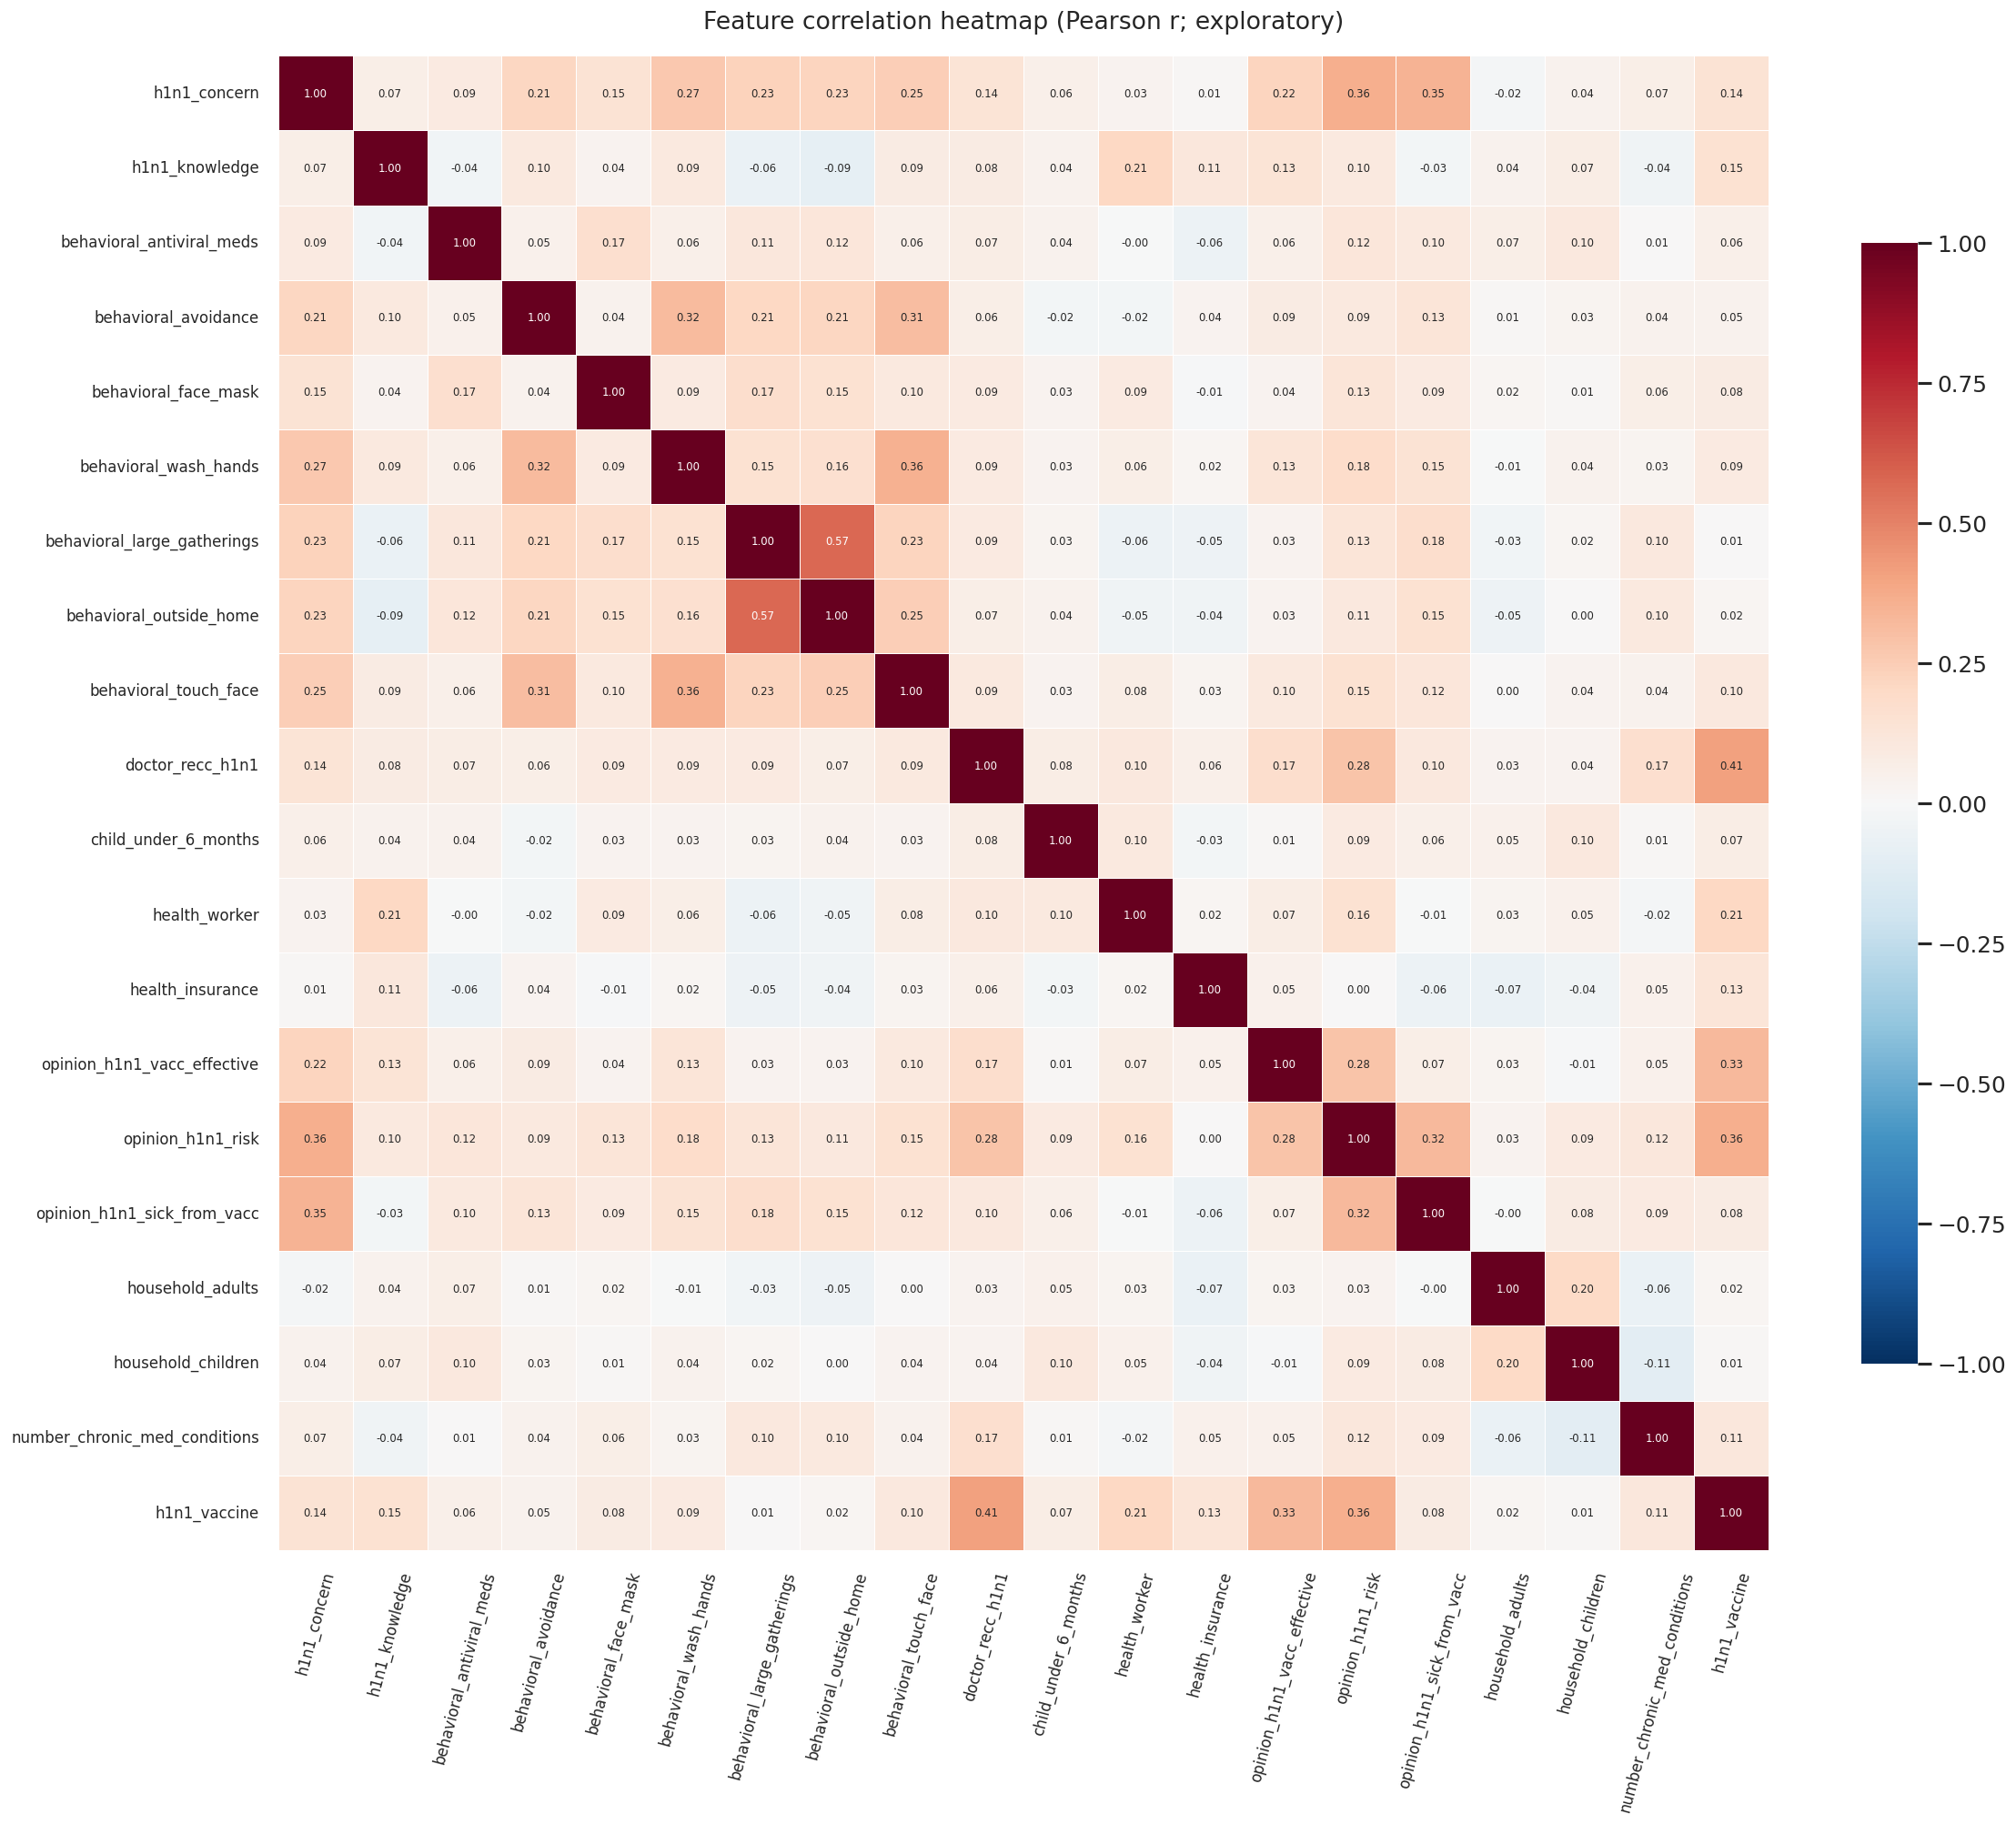

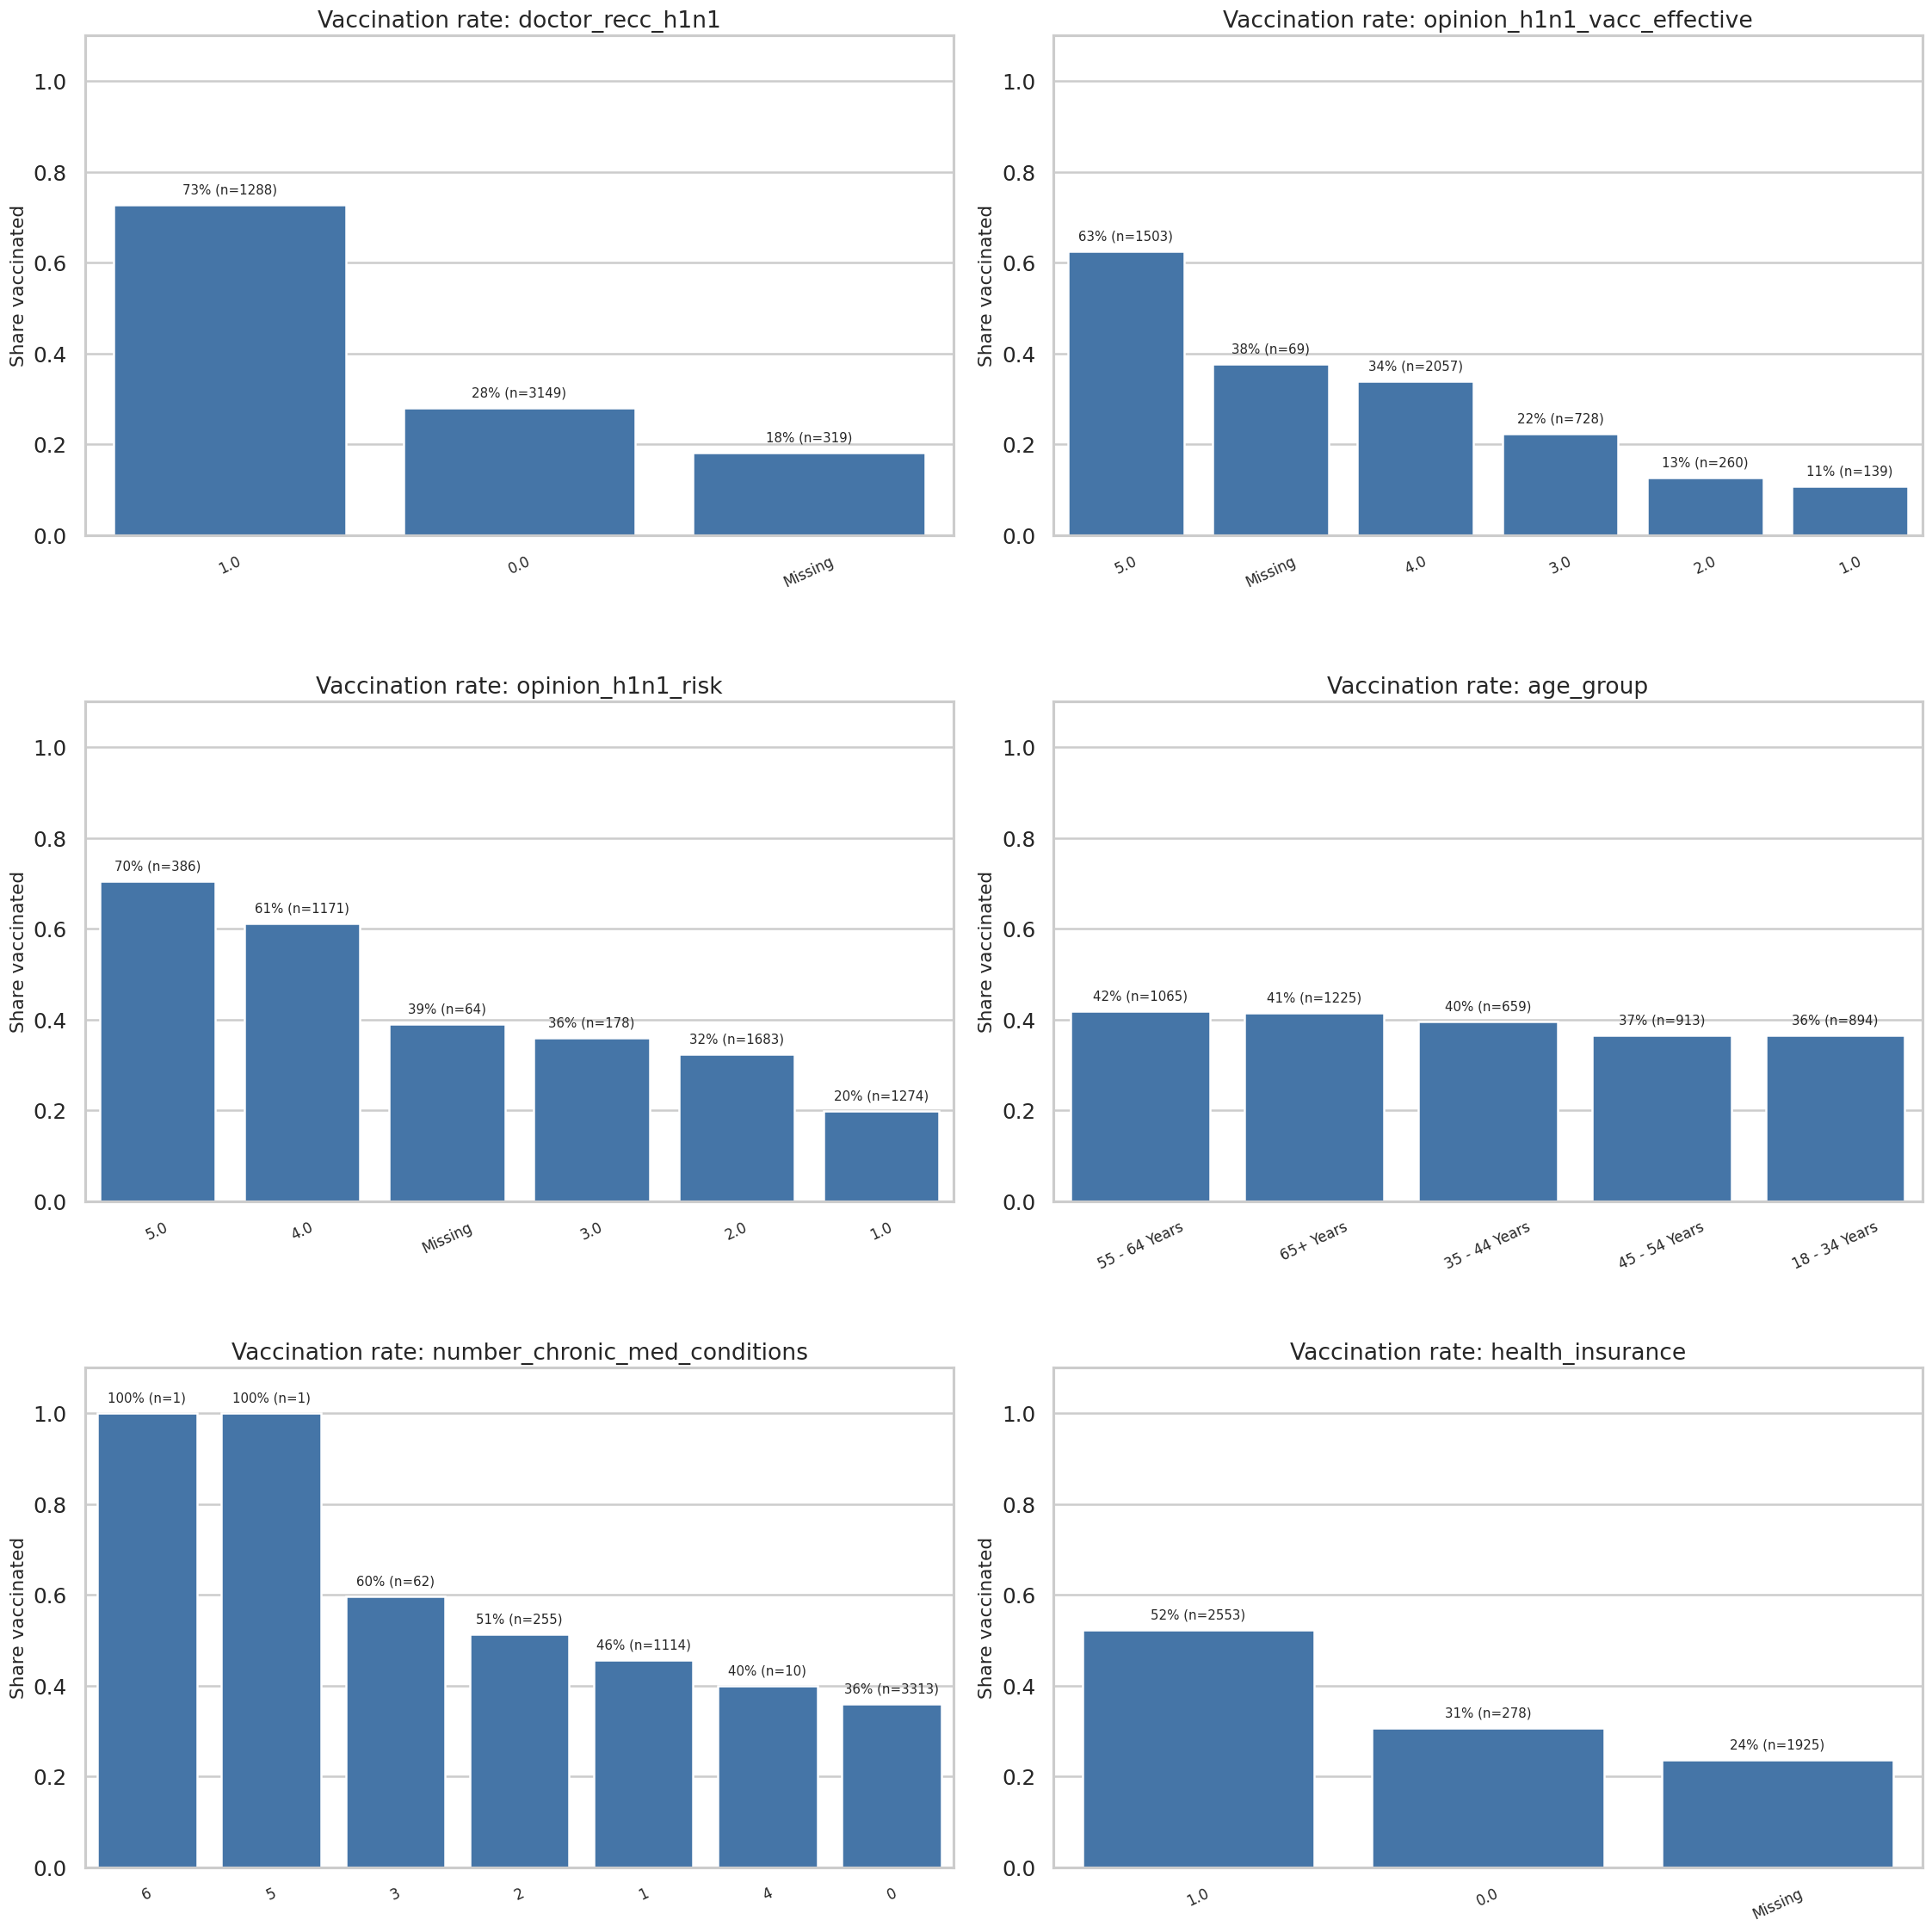

In [ ]:
# Larger, annotated correlation heatmap and easy-to-read vaccination-rate plots
num_cols = train[features].select_dtypes(include='number').columns.tolist()
cat_cols = [c for c in features if c not in num_cols]
correlations = train[num_cols + [TARGET]].corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(20,17))
sns.heatmap(correlations,annot=True,fmt='.2f',cmap='RdBu_r',center=0,
            vmin=-1,vmax=1,linewidths=.4,annot_kws={'size':7},
            cbar_kws={'shrink':.75},ax=ax)
ax.set_title('Feature correlation heatmap (Pearson r; exploratory)',pad=18)
ax.tick_params(axis='x',labelrotation=75,labelsize=10)
ax.tick_params(axis='y',labelsize=10)
plt.tight_layout();plt.show()

cols = ['doctor_recc_h1n1','opinion_h1n1_vacc_effective',
        'opinion_h1n1_risk','age_group','number_chronic_med_conditions','health_insurance']
fig,axs=plt.subplots(3,2,figsize=(19,19))
for ax,col in zip(axs.flat,cols):
    group=train.assign(category=train[col].astype('string').fillna('Missing')).groupby('category')[TARGET].agg(['mean','count'])
    group=group.sort_values('mean',ascending=False)
    sns.barplot(x=group.index.astype(str),y=group['mean'],color='#3575b7',ax=ax)
    ax.set_title('Vaccination rate: '+col);ax.set_ylim(0,1.10)
    ax.set_ylabel('Share vaccinated');ax.set_xlabel('')
    ax.tick_params(axis='x',rotation=25,labelsize=10)
    for j,(rate,n) in enumerate(zip(group['mean'],group['count'])):
        ax.text(j,rate+.025,f'{rate:.0%} (n={n})',ha='center',fontsize=9)
plt.tight_layout(h_pad=3);plt.show()

In [ ]:
# Category shift: unseen categories in test and missingness shifts
for c in cat_cols:
    unseen=set(test[c].dropna().unique())-set(train[c].dropna().unique())
    if unseen: print('Unseen test categories:',c,unseen)
print('Max absolute missingness shift (percentage points):',round((missing['Training %']-missing['Testing %']).abs().max(),2))
# Missingness can be informative; imputation is fitted only on training folds.
print('EDA complete. Record decisions and notable patterns in markdown before presenting.')

Max absolute missingness shift (percentage points): 1.81
EDA complete. Record decisions and notable patterns in markdown before presenting.


## 4. Hospitalisation assumptions: literature-informed scenario

The challenge assumes **everyone is infected**. Our target is whether a person would **accept** a vaccine, not whether they would be hospitalised. We therefore estimate hospitalisation risk externally:

`risk = base_risk × age_multiplier × (1 + chronic_k × chronic_count) × (1 − vacc_eff if vaccinated)`.

**Important:** the central estimates below are modelling assumptions, not coefficients fitted to the survey. CDC's ~274,304 hospitalisations / ~60.8 million *estimated cases* ≈ 0.45% per case; this is **not strictly per infection** nor specific to healthy 35–44-year-olds. The 0.5% baseline is a judgement informed by that scale. Age and chronic-condition effects are approximations, not published estimates for these exact bins. The 50% vaccine estimate is from a US hospitalisation study; protection conditional on infection is not directly identified by that study.

Sources: [CDC/Shrestha 2011](https://archive.cdc.gov/www_cdc_gov/h1n1flu/estimates_2009_h1n1.htm), [2009 H1N1 hospitalisation vaccine effectiveness study](https://pubmed.ncbi.nlm.nih.gov/23956169/), [systematic review](https://pubmed.ncbi.nlm.nih.gov/28302409/), [global severe-outcome risk factors](https://pubmed.ncbi.nlm.nih.gov/21750667/), [Hong Kong infection-hospitalisation estimates](https://pubmed.ncbi.nlm.nih.gov/24428855/).

**Warning:** survey age bands must be mapped to the requested five age bins approximately: the dataset has 18–34, 35–44, 45–54, 55–64, 65+. Check the printed category names below. Run sensitivity analysis; do not present scenario costs as actual observed hospital admissions.

In [ ]:
# ---- EDIT THESE PARAMETERS IF YOUR TEAM AGREES ON DIFFERENT ESTIMATES ----
VACCINE_COST = 500.0
HOSPITAL_COST = 25000.0

BASE_RISK = 0.005                 # 0.5% per infection: judgement-based reference
BASE_RISK_RANGE = (0.002, 0.012)
AGE_MULT = {'18-34': 0.8, '35-44': 1.0, '45-54': 1.2,
            '55-64': 1.7, '65+': 2.5}
CHRONIC_K = 0.5                 # each additional condition adds 50% relative risk
CHRONIC_K_RANGE = (0.25, 1.0)
VACC_EFF = 0.50                 # relative reduction in hospitalisation risk
VACC_EFF_RANGE = (0.13, 0.71)

print('Age categories in your dataset:', sorted(train['age_group'].dropna().unique()))

# Translate survey labels into the five age groups in the assignment.
def age_group_key(value):
    value = str(value).lower().replace('years', '').replace(' ', '')
    if '18-34' in value: return '18-34'
    if '35-44' in value: return '35-44'
    if '45-54' in value: return '45-54'
    if '55-64' in value: return '55-64'
    if '65+' in value or '65and' in value: return '65+'
    return None

def hospital_risks(frame, base=BASE_RISK, reduction=VACC_EFF,
                   chronic_k=CHRONIC_K, age_mult=AGE_MULT):
    age_keys = frame['age_group'].map(age_group_key)
    if age_keys.isna().any():
        print('Unknown age labels:', frame.loc[age_keys.isna(), 'age_group'].unique())
        raise ValueError('Age categories need mapping before risk calculation')
    age_factor = age_keys.map(age_mult).to_numpy(dtype=float)
    chronic = pd.to_numeric(frame['number_chronic_med_conditions'], errors='coerce')
    # Median imputation is a simple risk-model assumption; test alternatives.
    chronic = chronic.fillna(chronic.median()).clip(lower=0).to_numpy(dtype=float)
    risk_unvaccinated = np.clip(base * age_factor * (1 + chronic_k * chronic), 0, 1)
    risk_vaccinated = risk_unvaccinated * (1 - reduction)
    return risk_unvaccinated, risk_vaccinated

def expected_town_cost(y_true, dispatch, r0, r1):
    # y_true: would accept vaccine (0/1); dispatch: vaccine sent to home (0/1).
    # If no vaccine is sent to a willing person, town compensates $500.
    y = np.asarray(y_true, dtype=int)
    d = np.asarray(dispatch, dtype=int)
    vaccine_cost = VACCINE_COST * (d + (1-d)*y)
    hospital_cost = HOSPITAL_COST * (r0 - d*y*(r0-r1))
    total = vaccine_cost + hospital_cost
    return {'total': float(total.sum()), 'per_person': float(total.mean()),
            'vaccine': float(vaccine_cost.sum()), 'hospital': float(hospital_cost.sum()),
            'sent': int(d.sum()), 'wasted': int(((d==1)&(y==0)).sum()),
            'compensated': int(((d==0)&(y==1)).sum())}

def dispatch_from_probability(p, r0, r1):
    # Sending costs $500 extra when recipient refuses; if they accept, it avoids
    # $500 compensation and reduces expected hospital costs.
    # Threshold derived by comparing expected send vs do-not-send costs.
    cutoff = VACCINE_COST / (VACCINE_COST + HOSPITAL_COST * (r0-r1))
    return (np.asarray(p) >= cutoff).astype(int)

r0_all, r1_all = hospital_risks(train)
print('Mean estimated unvaccinated hospitalisation risk:', round(r0_all.mean(), 5))
print('Mean estimated vaccinated hospitalisation risk:', round(r1_all.mean(), 5))
print('Dispatch probability cutoffs:', pd.Series(VACCINE_COST / (
    VACCINE_COST + HOSPITAL_COST*(r0_all-r1_all))).describe())
print('Send nobody:', expected_town_cost(train[TARGET], np.zeros(len(train)), r0_all, r1_all))
print('Send everybody:', expected_town_cost(train[TARGET], np.ones(len(train)), r0_all, r1_all))

Age categories in your dataset: ['18 - 34 Years', '35 - 44 Years', '45 - 54 Years', '55 - 64 Years', '65+ Years']
Mean estimated unvaccinated hospitalisation risk: 0.00943
Mean estimated vaccinated hospitalisation risk: 0.00472
Dispatch probability cutoffs: count    4756.000000
mean        0.817568
std         0.078836
min         0.516129
25%         0.761905
50%         0.824742
75%         0.888889
max         0.909091
dtype: float64
Send nobody: {'total': 2058531.25, 'per_person': 432.82826955424724, 'vaccine': 937000.0, 'hospital': 1121531.25, 'sent': 0, 'wasted': 0, 'compensated': 1874}
Send everybody: {'total': 3265781.25, 'per_person': 686.6655277544155, 'vaccine': 2378000.0, 'hospital': 887781.25, 'sent': 4756, 'wasted': 2882, 'compensated': 0}


### Risk parameters for comparison with another AI

```json
{
  "base_risk": 0.005,
  "base_risk_range": [0.002, 0.012],
  "age_mult": {"18-34": 0.8, "35-44": 1.0, "45-54": 1.2, "55-64": 1.7, "65+": 2.5},
  "chronic_k": 0.5,
  "chronic_k_range": [0.25, 1.0],
  "vacc_eff": 0.5,
  "vacc_eff_range": [0.13, 0.71],
  "main_sources": ["CDC/Shrestha 2011", "US vaccine hospitalization case-control study 2013", "2017 vaccine meta-analysis", "global H1N1 risk factors 2011"]
}
```

The numerical age and chronic effects are *judgement-based*, not exact published estimates. Discuss the per-infection versus per-case distinction in your report.

## 5. Leakage-free split and preprocessing
Use a stratified 80/20 holdout. Fit imputers, encoders, and scaling **inside** the training-only pipelines; cross-validation refits them separately in every fold. Coded numerical variables are treated as ordered numeric features; nominal string categories are one-hot encoded.

In [ ]:
X=train[features].copy();y=train[TARGET].astype(int)
X_dev,X_hold,y_dev,y_hold=train_test_split(X,y,test_size=0.20,random_state=SEED,stratify=y)
# SimpleImputer's keep_empty_features is not needed with the observed columns.
num_pipe=Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),('scale',StandardScaler())])
cat_pipe=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
preprocess=ColumnTransformer([('numeric',num_pipe,num_cols),('categorical',cat_pipe,cat_cols)],remainder='drop',sparse_threshold=0)
print('Development:',X_dev.shape,'Holdout:',X_hold.shape)
print('Holdout is untouched until final assessment of model candidates.')

Development: (3804, 29) Holdout: (952, 29)
Holdout is untouched until final assessment of model candidates.


## 6. Compare strong, explainable models
We compare **Logistic Regression**, **Random Forest**, **Extra Trees**, **Histogram Gradient Boosting**, a **tuned Gradient Boosting** model, and a **simple probability ensemble**. Different model families provide useful diversity; no algorithm is guaranteed to win. The ensemble averages Logistic Regression and tuned Gradient Boosting probabilities. Hyperparameters are tuned on development data only.

**Selection metric:** estimated town cost per person under the stated scenario. We also report AUC, Brier score, accuracy and F1. We rank by cross-validated cost first to reduce reliance on one lucky holdout split.

In [ ]:
models = {
    'LogisticRegression': LogisticRegression(max_iter=1500, C=0.5, random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=250,min_samples_leaf=4,n_jobs=-1,random_state=SEED),
    'ExtraTrees': ExtraTreesClassifier(n_estimators=250,min_samples_leaf=3,n_jobs=-1,random_state=SEED),
    'HistGradientBoosting': HistGradientBoostingClassifier(max_iter=160,learning_rate=.05,max_leaf_nodes=15,random_state=SEED)
}
cv = StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
# Tune gradient boosting using a probability-sensitive objective.
tuning_pipeline = Pipeline([('prep',clone(preprocess)),
                            ('model',HistGradientBoostingClassifier(random_state=SEED))])
search = RandomizedSearchCV(
    tuning_pipeline,
    {'model__max_iter':[100,160,220],
     'model__learning_rate':[.025,.05,.08],
     'model__max_leaf_nodes':[7,15,25],
     'model__min_samples_leaf':[15,30,50],
     'model__l2_regularization':[0,.1,1.]},
    n_iter=12,scoring='neg_log_loss',cv=cv,n_jobs=-1,random_state=SEED)
search.fit(X_dev,y_dev)
models['TunedGradientBoosting'] = clone(search.best_estimator_.named_steps['model'])
print('Best tuned parameters:',search.best_params_)
print('Best cross-validation log loss:',round(-search.best_score_,4))

Best tuned parameters: {'model__min_samples_leaf': 15, 'model__max_leaf_nodes': 7, 'model__max_iter': 220, 'model__learning_rate': 0.05, 'model__l2_regularization': 0}
Best cross-validation log loss: 0.457


In [ ]:
# Evaluate using out-of-fold predictions and a separate holdout
# Out-of-fold = each prediction comes from a model trained without that row.
def classification_metrics(ytrue,prob,decisions):
    return {'roc_auc':roc_auc_score(ytrue,prob),
            'avg_precision':average_precision_score(ytrue,prob),
            'log_loss':log_loss(ytrue,prob,labels=[0,1]),
            'brier':brier_score_loss(ytrue,prob),
            'accuracy':accuracy_score(ytrue,decisions),
            'f1':f1_score(ytrue,decisions,zero_division=0)}

r0_dev,r1_dev = hospital_risks(X_dev)
r0_hold,r1_hold = hospital_risks(X_hold)
results=[];fitted={};oof_probs={};hold_probs={};hold_dispatch={}
for name,model in models.items():
    print('Evaluating:',name)
    pipe=Pipeline([('prep',clone(preprocess)),('model',clone(model))])
    oof_probs[name]=cross_val_predict(pipe,X_dev,y_dev,cv=cv,method='predict_proba',n_jobs=-1)[:,1]
    pipe.fit(X_dev,y_dev)
    fitted[name]=pipe
    hold_probs[name]=pipe.predict_proba(X_hold)[:,1]

# Add a transparent ensemble (same training folds and holdout split).
oof_probs['Ensemble']=.5*oof_probs['LogisticRegression']+.5*oof_probs['TunedGradientBoosting']
hold_probs['Ensemble']=.5*hold_probs['LogisticRegression']+.5*hold_probs['TunedGradientBoosting']

for name in hold_probs:
    oof_dec=dispatch_from_probability(oof_probs[name],r0_dev,r1_dev)
    hold_dec=dispatch_from_probability(hold_probs[name],r0_hold,r1_hold)
    hold_dispatch[name]=hold_dec
    cv_cost=expected_town_cost(y_dev,oof_dec,r0_dev,r1_dev)
    hold_cost=expected_town_cost(y_hold,hold_dec,r0_hold,r1_hold)
    results.append({'model':name,'oof_cost_per_person':cv_cost['per_person'],
                    'holdout_cost_per_person':hold_cost['per_person'],
                    'holdout_total_cost':hold_cost['total'],
                    'sent_holdout':hold_cost['sent'],'wasted_holdout':hold_cost['wasted'],
                    'compensated_holdout':hold_cost['compensated'],
                    **classification_metrics(y_hold,hold_probs[name],hold_dec)})
comparison=pd.DataFrame(results).sort_values(['oof_cost_per_person','holdout_cost_per_person']).reset_index(drop=True)
champion=comparison.iloc[0]['model']
print('Best by development out-of-fold estimated cost:',champion)
display(comparison.round(4))
print('IMPORTANT: cost uses assumed hospitalisation rates, not measured admissions.')

Evaluating: LogisticRegression
Evaluating: RandomForest
Evaluating: ExtraTrees
Evaluating: HistGradientBoosting
Evaluating: TunedGradientBoosting
Best by development out-of-fold estimated cost: HistGradientBoosting


,model,oof_cost_per_person,holdout_cost_per_person,holdout_total_cost,sent_holdout,wasted_holdout,compensated_holdout,roc_auc,avg_precision,log_loss,brier,accuracy,f1
0,HistGradientBoosting,417.6073,425.8830,405440.625,132,16,259,0.8455,0.7943,0.4703,0.1526,0.7111,0.4576
1,TunedGradientBoosting,417.7814,424.4945,404118.750,122,12,265,0.8465,0.8015,0.4684,0.1517,0.7090,0.4427
2,Ensemble,418.0435,424.1071,403750.000,124,12,263,0.8470,0.8005,0.4679,0.1517,0.7111,0.4489
3,LogisticRegression,419.0408,424.6356,404253.125,138,15,252,0.8398,0.7913,0.4793,0.1558,0.7195,0.4795
4,ExtraTrees,420.8834,427.7311,407200.000,66,6,315,0.8386,0.7757,0.4909,0.1592,0.6628,0.2721
5,RandomForest,421.7156,428.7027,408125.000,58,5,322,0.8305,0.7699,0.5003,0.1636,0.6565,0.2448


IMPORTANT: cost uses assumed hospitalisation rates, not measured admissions.


## 7. Robustness and performance analysis
Inspect confusion matrices, probability calibration, and performance variation across folds. The 3-fold OOF cost is a useful model-development check; the holdout cost is an independent comparison but **selecting the winner on that same holdout still introduces selection bias**. Report this limitation. AUC does not directly measure economic cost.

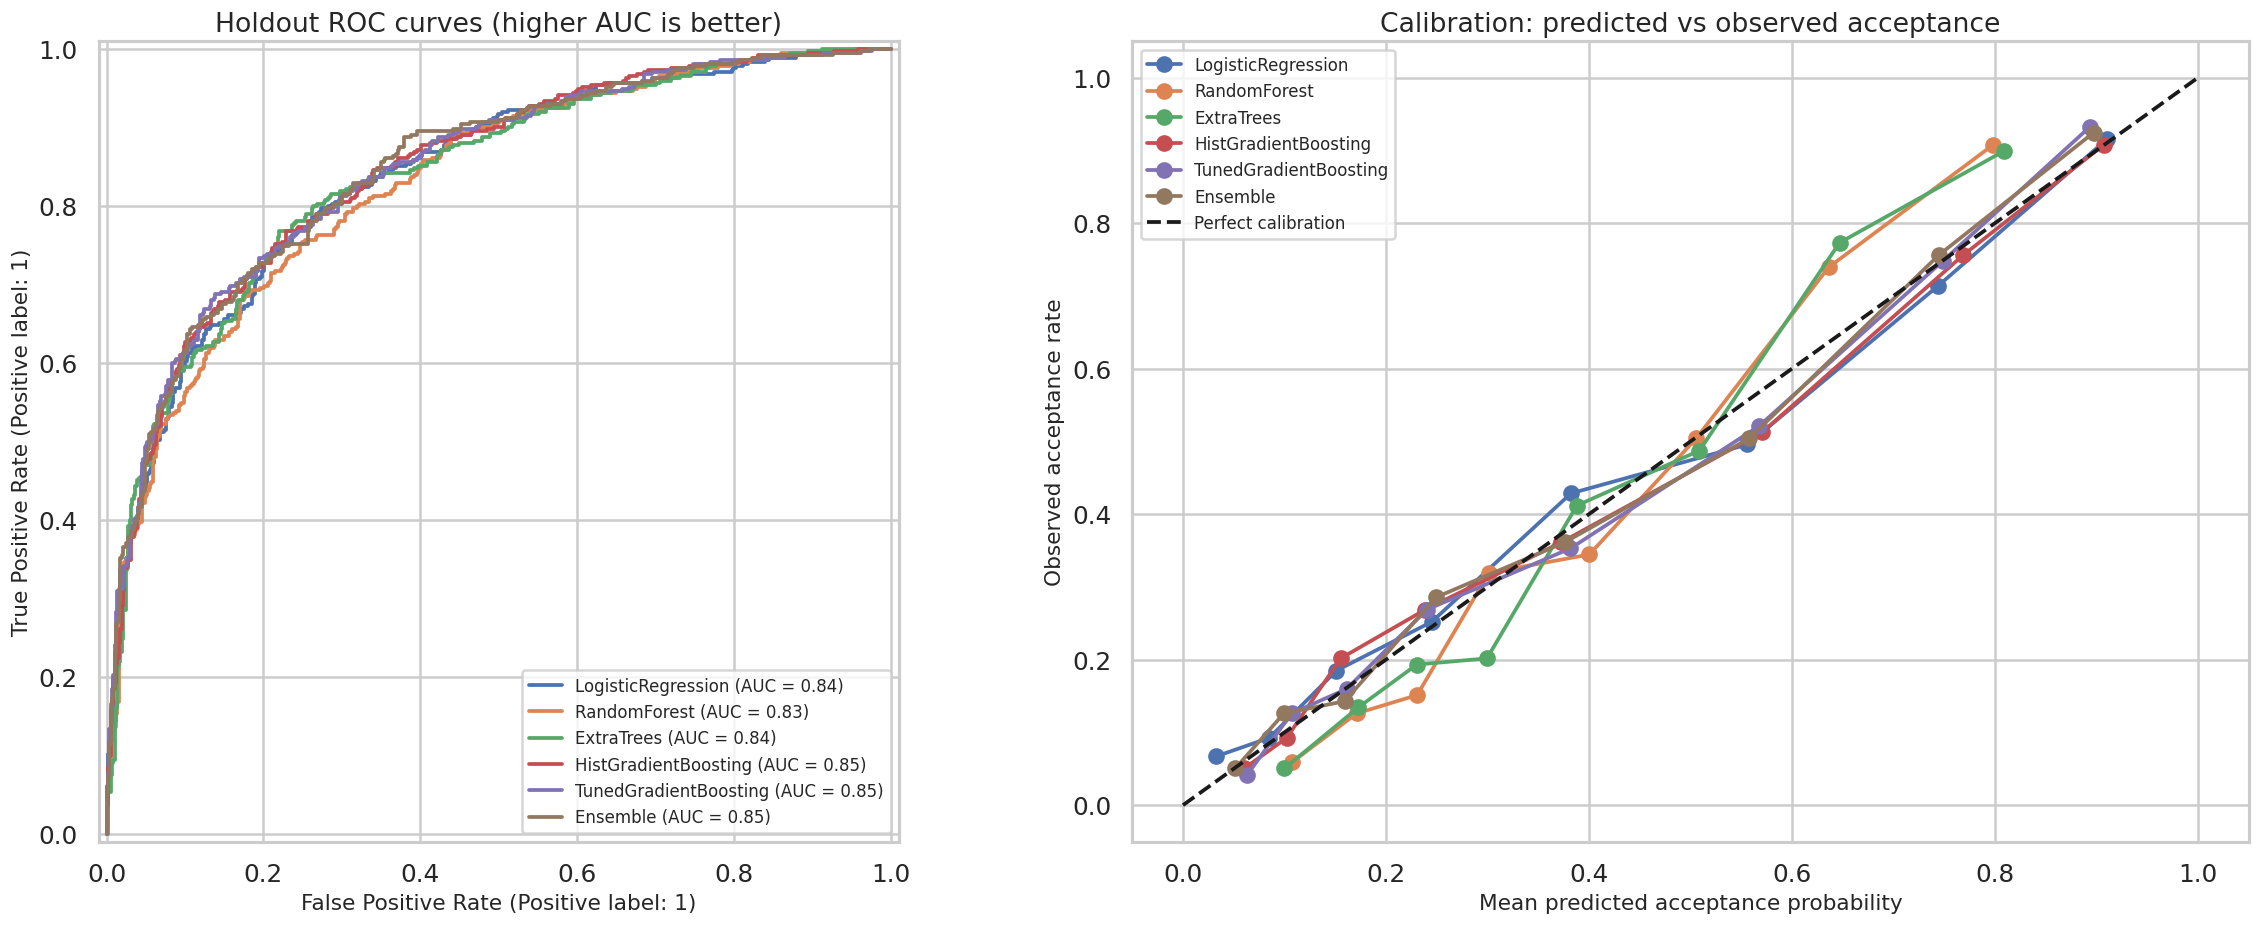

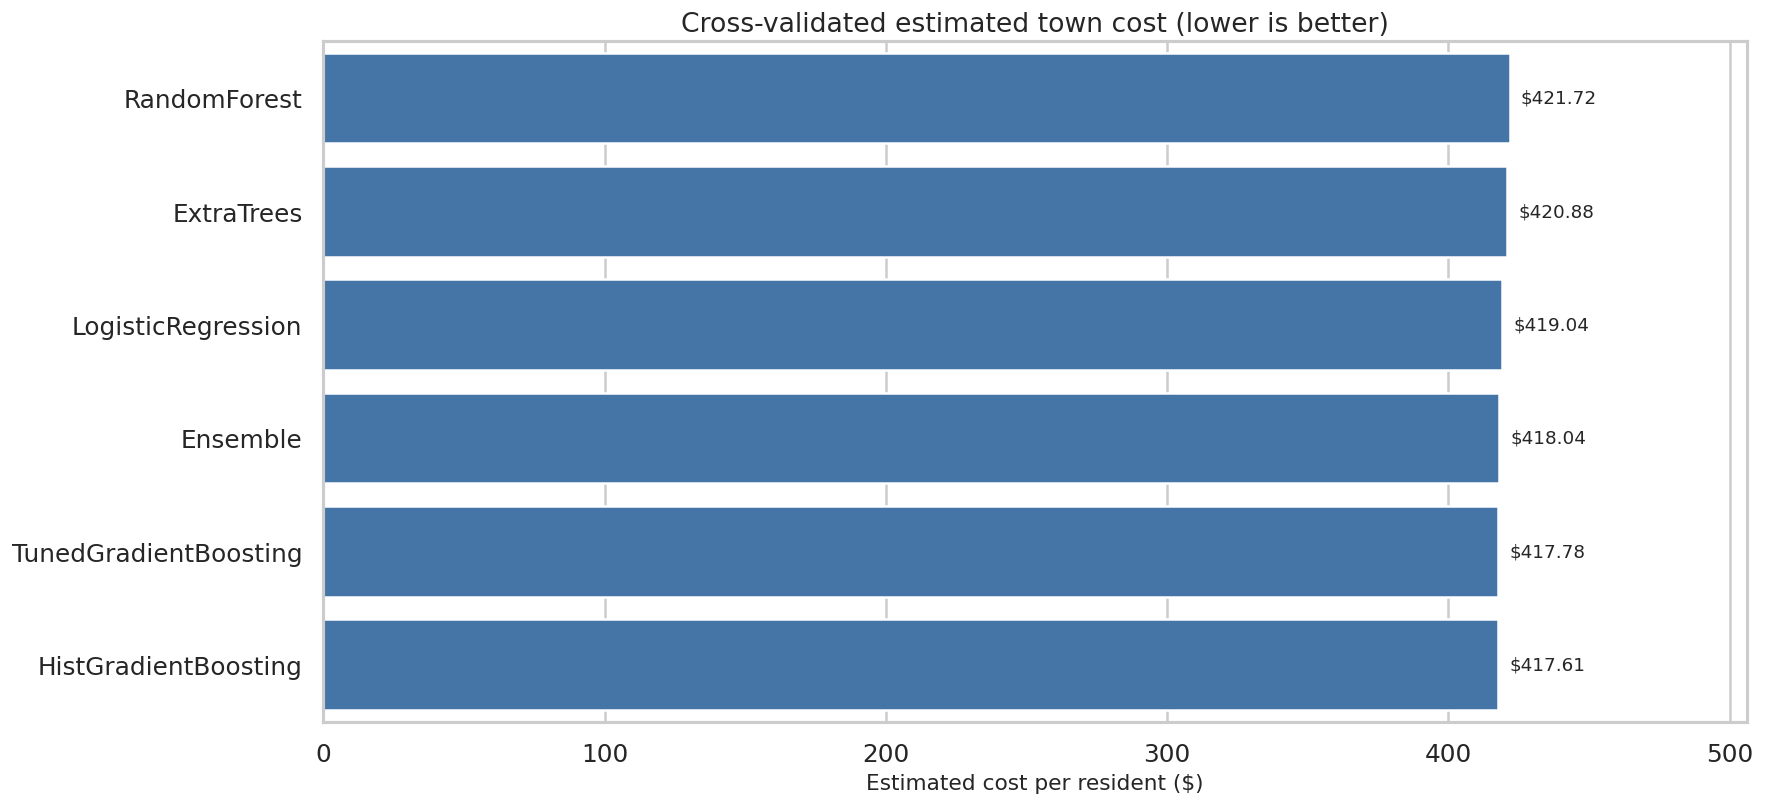

In [ ]:
# Larger ROC and probability calibration plots
fig,axs=plt.subplots(1,2,figsize=(20,8))
for name,prob in hold_probs.items():
    RocCurveDisplay.from_predictions(y_hold,prob,name=name,ax=axs[0])
    frac_pos,mean_pred=calibration_curve(y_hold,prob,n_bins=8,strategy='quantile')
    axs[1].plot(mean_pred,frac_pos,marker='o',label=name)
axs[0].set_title('Holdout ROC curves (higher AUC is better)')
axs[0].legend(fontsize=10)
axs[1].plot([0,1],[0,1],'k--',label='Perfect calibration')
axs[1].set_title('Calibration: predicted vs observed acceptance')
axs[1].set_xlabel('Mean predicted acceptance probability')
axs[1].set_ylabel('Observed acceptance rate')
axs[1].legend(fontsize=10)
plt.tight_layout();plt.show()

fig,ax=plt.subplots(figsize=(15,7))
rankplot=comparison.sort_values('oof_cost_per_person',ascending=False)
sns.barplot(data=rankplot,x='oof_cost_per_person',y='model',color='#3575b7',ax=ax)
for i,v in enumerate(rankplot['oof_cost_per_person']):
    ax.text(v+4,i,f'${v:,.2f}',va='center',fontsize=11)
ax.set_xlim(0,rankplot['oof_cost_per_person'].max()*1.20)
ax.set_title('Cross-validated estimated town cost (lower is better)')
ax.set_xlabel('Estimated cost per resident ($)');ax.set_ylabel('')
plt.tight_layout();plt.show()

In [ ]:
# Cost variability across folds for the strongest non-ensemble candidate
base_champion=champion if champion!='Ensemble' else 'TunedGradientBoosting'
fold_records=[]
for fold,(tr,va) in enumerate(cv.split(X_dev,y_dev),1):
    model=clone(fitted[base_champion])
    model.fit(X_dev.iloc[tr],y_dev.iloc[tr])
    X_val=X_dev.iloc[va];y_val=y_dev.iloc[va]
    p=model.predict_proba(X_val)[:,1]
    a,b=hospital_risks(X_val)
    cost=expected_town_cost(y_val,dispatch_from_probability(p,a,b),a,b)
    fold_records.append({'fold':fold,'cost_per_person':cost['per_person'],'auc':roc_auc_score(y_val,p)})
fold_results=pd.DataFrame(fold_records)
display(fold_results.round(3))
print('Fold cost standard deviation:',round(fold_results.cost_per_person.std(),2))

,fold,cost_per_person,auc
0,1,417.530,0.853
1,2,417.429,0.843
2,3,417.863,0.854


Fold cost standard deviation: 0.23


## 8. Sensitivity analysis — crucial for scientific validity

We vary the **per-infection baseline risk**, the extra risk from chronic conditions, and hospitalisation vaccine effectiveness over plausible ranges. These scenarios are **not confidence intervals**: they combine published evidence with judgement. A model that ranks first only under one assumption is not a robust winner.

In [ ]:
scenarios = []
for base in [BASE_RISK_RANGE[0], BASE_RISK, BASE_RISK_RANGE[1]]:
    for chronic_k in [CHRONIC_K_RANGE[0], CHRONIC_K, CHRONIC_K_RANGE[1]]:
        for efficacy in [VACC_EFF_RANGE[0], VACC_EFF, VACC_EFF_RANGE[1]]:
            risk0, risk1 = hospital_risks(X_hold, base=base,
                                          chronic_k=chronic_k, reduction=efficacy)
            model_costs = {}
            for name, probability in hold_probs.items():
                decisions = dispatch_from_probability(probability, risk0, risk1)
                model_costs[name] = expected_town_cost(
                    y_hold, decisions, risk0, risk1)['per_person']
            best_model = min(model_costs, key=model_costs.get)
            scenarios.append({'base_risk': base, 'chronic_k': chronic_k,
                              'vaccine_effectiveness': efficacy,
                              'best_model': best_model,
                              'best_cost_per_person': model_costs[best_model]})
scenario_df = pd.DataFrame(scenarios)
display(scenario_df)
print('Number of scenarios won by each model:')
display(scenario_df['best_model'].value_counts())

,base_risk,chronic_k,vaccine_effectiveness,best_model,best_cost_per_person
0,0.002,0.25,0.13,LogisticRegression,284.315848
1,0.002,0.25,0.50,HistGradientBoosting,281.918330
2,0.002,0.25,0.71,TunedGradientBoosting,280.470207
3,0.002,0.50,0.13,LogisticRegression,292.884349
4,0.002,0.50,0.50,HistGradientBoosting,289.600840
5,0.002,0.50,0.71,TunedGradientBoosting,287.881303
6,0.002,1.00,0.13,LogisticRegression,309.982090
7,0.002,1.00,0.50,HistGradientBoosting,305.238971
8,0.002,1.00,0.71,TunedGradientBoosting,302.004307
9,0.005,0.25,0.13,LogisticRegression,414.806657


Number of scenarios won by each model:


,count
best_model,
TunedGradientBoosting,11
LogisticRegression,6
HistGradientBoosting,5
Ensemble,4
ExtraTrees,1


## 9. Explainability and failure analysis
Permutation importance uses the **untouched holdout** for explanation only, with ROC-AUC as a model-independent predictive diagnostic. This is not causal evidence. Explain mistakes in high-risk groups and missing-data groups; avoid claiming that demographic attributes cause acceptance.

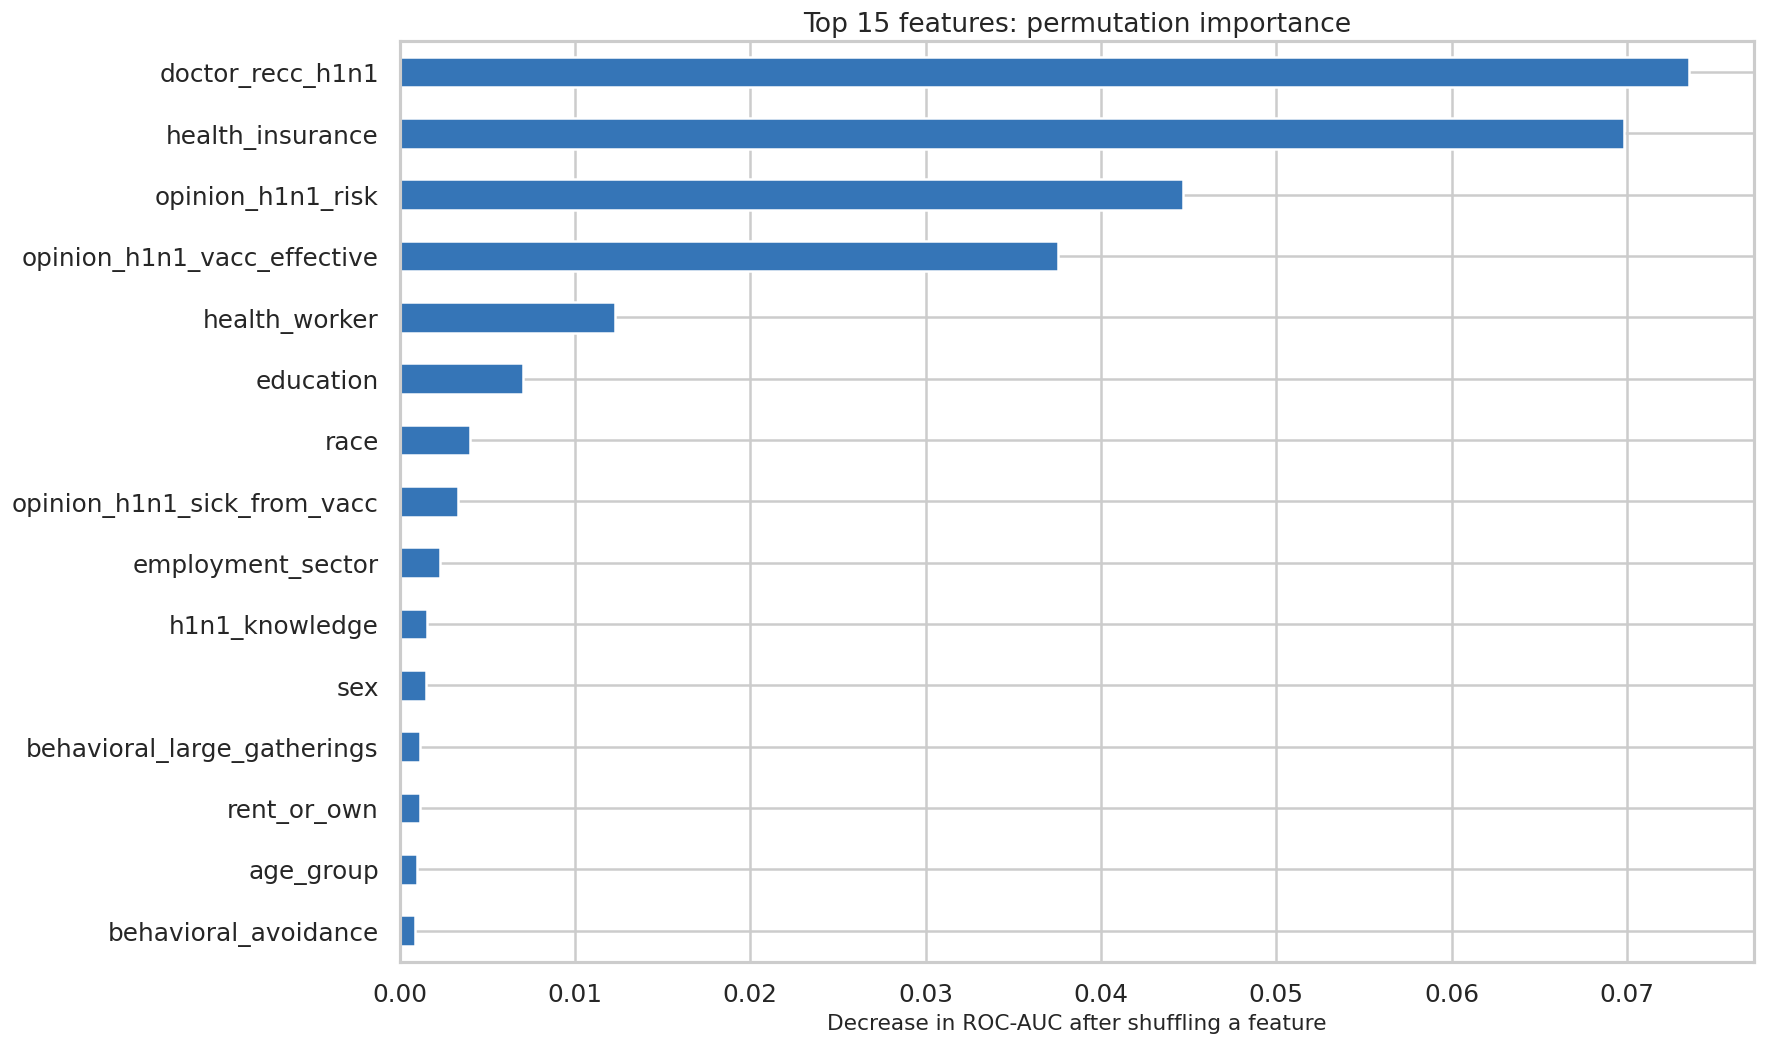

Acceptance classification error rate: 0.215


,mean,count
age_group,,
18 - 34 Years,0.220,173
35 - 44 Years,0.195,128
45 - 54 Years,0.194,186
55 - 64 Years,0.246,191
65+ Years,0.215,274


In [ ]:
# Explainable AI: permutation importance of the strongest fitted single model
base_champion=champion if champion!='Ensemble' else 'TunedGradientBoosting'
importance=permutation_importance(fitted[base_champion],X_hold,y_hold,
                                  n_repeats=4,random_state=SEED,scoring='roc_auc',n_jobs=-1)
imp=pd.Series(importance.importances_mean,index=features).sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(15,9))
imp.head(15).sort_values().plot.barh(ax=ax,color='#3575b7')
ax.set_title('Top 15 features: permutation importance')
ax.set_xlabel('Decrease in ROC-AUC after shuffling a feature')
plt.tight_layout();plt.show()

# Errors in the vaccination acceptance probability model (0.5 cutoff).
errors=X_hold.copy()
errors['actual']=np.asarray(y_hold)
errors['probability']=hold_probs[champion]
errors['predicted']=(errors['probability']>=.5).astype(int)
errors['incorrect']=errors['actual']!=errors['predicted']
print('Acceptance classification error rate:',round(errors.incorrect.mean(),3))
display(errors.groupby('age_group',dropna=False)['incorrect'].agg(['mean','count']).round(3))

## 10. Generate the five best submission files
We refit each model on all training rows. If the **ensemble** ranks in the top five, it averages the two separately refitted base models. The example file defines the required respondent ordering and columns.

**Crucial ambiguity:** the example file does not unambiguously prove whether the graders expect probabilities of acceptance, predicted acceptance labels, or dispatch decisions. The code below writes **0/1 dispatch decisions** under our economic interpretation. Confirm this interpretation with your tutor before uploading. Never submit the five files without checking the specification.

In [ ]:
# Refit on ALL labelled data and save five ranked submissions
outdir=os.path.join(DATA_DIR,'hackathon_outputs_v2')
os.makedirs(outdir,exist_ok=True)
r0_test,r1_test=hospital_risks(test)

# Fit all individual models once. The ensemble reuses their probabilities.
test_probs={}
for name,model in models.items():
    final_pipe=Pipeline([('prep',clone(preprocess)),('model',clone(model))])
    final_pipe.fit(X,y)
    test_probs[name]=final_pipe.predict_proba(test[features])[:,1]
test_probs['Ensemble']=.5*test_probs['LogisticRegression']+.5*test_probs['TunedGradientBoosting']

submission_summary=[]
for rank,name in enumerate(comparison.model.head(5),1):
    decisions=dispatch_from_probability(test_probs[name],r0_test,r1_test)
    submission=example[[ID]].copy()
    submission[TARGET]=decisions.astype(int)
    assert submission.shape==example.shape
    assert submission[ID].equals(example[ID])
    assert submission[TARGET].isin([0,1]).all()
    filename=f'submission_{rank}_{name}.csv'
    submission.to_csv(os.path.join(outdir,filename),index=False)
    submission_summary.append({'rank':rank,'model':name,'file':filename,
                               'vaccines_sent':int(decisions.sum())})
summary=pd.DataFrame(submission_summary)
display(summary)
comparison.to_csv(os.path.join(outdir,'validation_comparison.csv'),index=False)
scenario_df.to_csv(os.path.join(outdir,'sensitivity_analysis.csv'),index=False)
summary.to_csv(os.path.join(outdir,'model_ranking.csv'),index=False)
print('Files saved in:',outdir)

,rank,model,file,vaccines_sent
0,1,HistGradientBoosting,submission_1_HistGradientBoosting.csv,716
1,2,TunedGradientBoosting,submission_2_TunedGradientBoosting.csv,665
2,3,Ensemble,submission_3_Ensemble.csv,684
3,4,LogisticRegression,submission_4_LogisticRegression.csv,724
4,5,ExtraTrees,submission_5_ExtraTrees.csv,371


Files saved in: /content/drive/MyDrive/hackathon_outputs_v2


## 11. Save outputs and submit
**Colab:** run the next cell to download a ZIP containing five CSV predictions and supporting tables. Verify the example file's two columns and the respondent ordering. Upload the **five ranked CSV files** to Canvas before the hackathon deadline. Do **not** submit the example file as a prediction.

**Team documentation:** add the GitHub organisation URL and shared Colab Editor URL to the first slide; commit the complete notebook, plots and results to public GitHub during the hackathon. Record contributors, experiment times and decisions. Keep the notebook reproducible from the original three CSV inputs.

In [ ]:
# Zip the 5 submission files + validation tables
zip_path=shutil.make_archive(os.path.join(DATA_DIR,'Dataset_B_five_submissions_v2'),'zip',outdir)
print('ZIP created:',zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('Open the ZIP directly from:',zip_path)